# 06b — Regla v2 con enfriamiento y validación fuera de muestra

**Capa 7 — KPIs** · Regla v2 y validación fuera de muestra

## Por qué falló la regla v1

El backtest del notebook 06 mostró dos cosas distintas:
- **El detector funciona.** En la puntocom, el rojo se encendió 11 semanas antes del peak (16 sin persistencia), y 2008 y 2022, que no fueron burbujas en el Nasdaq, no se marcaron.
- **La regla v1 protege poco.** En el Nasdaq la caída máxima solo baja de −77,4% a −73,2%. Frente al placebo queda en el percentil ~14 en A (aporta algo) y ~49 en B (igual al azar).

**Diagnóstico:** el BSADF mide si el precio está *acelerando*. En el peak el precio deja de acelerar, el estadístico baja y el semáforo vuelve a verde. La v1 vuelve entonces al 100% justo cuando empieza la caída (en 2000, en mayo, con el índice ya 20-30% abajo). **El riesgo está después de la burbuja**, no durante ella.

## La regla v2: enfriamiento de 52 semanas

| Situación | v1 | v2 |
|---|---|---|
| Semáforo en rojo | 50% | 50% |
| Termina el episodio rojo | Vuelve a 100% si está verde | **Se mantiene en 50% durante 52 semanas** y luego vuelve a 100% |
| Rojo nuevo durante el enfriamiento | — | El contador se reinicia cuando ese rojo termine |
| Amarillo | Mantiene la exposición | Mantiene la exposición |

**Justificación económica:** las caídas posteriores a una burbuja suelen durar entre 1 y 3 años (Nasdaq 2000-2002 ≈ 2,5 años). Un año de enfriamiento cubre la fase más violenta sin quedar fuera del mercado indefinidamente. Mismos supuestos que la v1: ejecución en *t+1*, nueva exposición desde el retorno de *t+2*, caja al 0% y costo 0% (sensibilidad 0,1%).

## Cómo se controla haber cambiado la regla después de ver resultados

Cambiar una regla después de ver cómo le fue a la anterior es riesgoso: es fácil terminar con una regla ajustada a la historia que se miró. Para controlarlo:
1. **La v2 y sus parámetros (52 semanas) se fijaron antes de evaluarla.** 26 y 104 semanas se reportan solo como sensibilidad; no se elige la mejor.
2. **Validación fuera de muestra:** se evalúa en burbujas que **no** se usaron para diseñar la regla (Nikkei 1989, Shanghái 2007 y 2015, Bitcoin 2021), con los mismos valores críticos y la misma persistencia.
3. **Criterio de éxito fijado antes de ver los resultados:** la v2 se valida si, en la mayoría de los episodios fuera de muestra evaluables, (a) reduce la caída máxima frente a mantener el 100% **y** (b) su percentil placebo es menor al 20%.
4. Si no se cumple, **no se prueban otras variantes**, y el KPI IL5 se presenta como calidad de detección, no como retorno.

La lógica vive en `src/backtest.py` (`exposicion_objetivo_v2`, `evaluar_serie`, `tabla_ventana`); la v1 se conserva sin cambios.

In [1]:
import sys
import logging
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src import config as C
from src import ingesta as I
from src import features as F
from src import backtest as B

# Nivel ERROR: muestra exclusiones y alertas, pero no los miles de avisos de días con volumen 0 del Nikkei
logging.basicConfig(level=logging.ERROR, format="%(levelname)-8s %(name)s | %(message)s",
                    stream=sys.stdout, force=True)
pd.set_option("display.width", 200)

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#898781", "ytick.color": "#898781",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})
AZUL, NARANJA, GRIS, ROJO = "#2a78d6", "#eb6834", "#52514e", "#d03b3b"

FORMATO = {"caida_maxima": "{:.1%}", "retorno_anual": "{:.1%}", "volatilidad_anual": "{:.1%}", "sharpe": "{:.2f}",
           "retorno_total": "{:.0%}", "cambios_exposicion": "{:.0f}", "pct_tiempo_reducida": "{:.1%}",
           "percentil_placebo": "{:.1f}"}
def mostrar(tabla):
    # Formatea una tabla de métricas (filas = métricas); NaN = no aplica
    return tabla.apply(lambda fila: fila.map(
        lambda v: "no aplica" if pd.isna(v) else FORMATO.get(fila.name, "{}").format(v)), axis=1)

def semaforo_de(validados, ticker):
    # Semáforo vigente (BSADF 260 semanas + persistencia 6) y precio semanal de una serie validada
    semanal = F.a_semanal(validados[validados["ticker"] == ticker])
    colores = F.senales_bsadf(semanal).set_index("fecha")["semaforo"]
    return semanal[ticker], colores

## 1. La regla v2 en un ejemplo

Para ver la lógica sin ruido, se aplica a una secuencia inventada de colores con un enfriamiento de 4 semanas (en el backtest es de 52):

In [2]:
ejemplo = pd.Series(["verde"] * 2 + ["rojo"] * 3 + ["verde"] * 5 + ["rojo"] * 2 + ["amarillo"] * 3 + ["verde"] * 3)
pd.DataFrame({"semáforo": ejemplo, "v1": B.exposicion_objetivo(ejemplo).map("{:.0%}".format),
              "v2 (enfriamiento 4)": B.exposicion_objetivo_v2(ejemplo, 4).map("{:.0%}".format)}).T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
semáforo,verde,verde,rojo,rojo,rojo,verde,verde,verde,verde,verde,rojo,rojo,amarillo,amarillo,amarillo,verde,verde,verde
v1,100%,100%,50%,50%,50%,100%,100%,100%,100%,100%,50%,50%,50%,50%,50%,100%,100%,100%
v2 (enfriamiento 4),100%,100%,50%,50%,50%,50%,50%,50%,50%,100%,50%,50%,50%,50%,50%,50%,100%,100%


**Cómo leerlo:** tras el primer episodio rojo, la v1 vuelve a 100% de inmediato. La v2 se mantiene 4 semanas más en 50% y vuelve a 100% en la quinta. En el segundo episodio, el amarillo no interrumpe el enfriamiento: el conteo sigue y la exposición queda en 50% hasta completarlo.

## 2. Verificación del placebo de la cartera B

El placebo debe replicar, **acción por acción**, el número de episodios de exposición reducida y su duración (y por lo tanto el % del tiempo reducido). En el notebook 06 cada acción recibe sus propias 1.000 exposiciones aleatorias, generadas con sus duraciones. Se verifica con los datos:

In [3]:
validados = pd.read_csv(C.DIR_PROCESSED / "precios_validados.csv", parse_dates=["fecha"])
panel = F.construir_panel(validados)
ACCIONES = list(C.UNIVERSO)
INICIO_B = pd.Timestamp("2018-01-05")
precios_b = panel.pivot(index="fecha", columns="ticker", values="adj_close")[ACCIONES]
colores_b = panel.pivot(index="fecha", columns="ticker", values="semaforo")[ACCIONES]
retornos_b = precios_b.pct_change().loc[INICIO_B:]

def exposiciones_b(regla, enfriamiento=C.SEMANAS_ENFRIAMIENTO):
    return pd.DataFrame({t: B.exposicion_efectiva(B.objetivo_regla(colores_b[t].dropna(), regla, enfriamiento))
                         for t in ACCIONES}).reindex(retornos_b.index)

expo_b = {"v1": exposiciones_b("v1"), "v2": exposiciones_b("v2")}
placebo_b = {regla: {t: B.exposiciones_placebo(expo_b[regla][t], 1000, semilla=C.SEMILLA_MC + i)
                     for i, t in enumerate(ACCIONES)} for regla in expo_b}

verificacion = pd.DataFrame([{
    "acción": t,
    "% reducido (regla v1)": (expo_b["v1"][t] < 1).mean(),
    "% reducido (placebo, promedio)": (placebo_b["v1"][t] < 1).mean(),
    "episodios (regla v1)": len(B.episodios(expo_b["v1"][t] < 1)),
    "episodios (placebo, mín-máx)": "{}-{}".format(*[f(len(B.episodios(fila < 1)) for fila in placebo_b["v1"][t])
                                                    for f in (min, max)]),
} for t in ACCIONES]).set_index("acción")
verificacion.style.format({"% reducido (regla v1)": "{:.1%}", "% reducido (placebo, promedio)": "{:.1%}"})

,% reducido (regla v1),"% reducido (placebo, promedio)",episodios (regla v1),"episodios (placebo, mín-máx)"
acción,,,,
NVDA,23.2%,23.2%,3,3-3
MSFT,6.3%,6.3%,2,2-2
GOOGL,15.0%,15.0%,2,2-2
META,7.2%,7.2%,3,3-3
AMD,5.2%,5.2%,2,2-2
AVGO,12.6%,12.6%,1,1-1
TSM,18.2%,18.2%,4,4-4
ORCL,0.0%,0.0%,0,0-0
AMZN,8.9%,8.9%,1,1-1


**Cómo leerlo:** para cada acción, el % del tiempo reducido y el número de episodios del placebo son **idénticos** a los de la regla real; solo cambian las fechas. La v1 queda reportada como primer resultado.

*Nota:* esta verificación revisa el número y la duración de los episodios. Que las fechas sean realmente al azar lo verifica `tests/test_backtest.py`.

## 3. Dentro de muestra: carteras A y B con v1 y v2

### 3.1 Cartera A: Nasdaq desde 1994

In [4]:
crudo_a = pd.read_csv(C.DIR_RAW / "IXIC_desde_1990.csv", parse_dates=["fecha"])
validado_a, _, _ = I.validar_universo(crudo_a, ["^IXIC"])
precio_a, colores_a = semaforo_de(validado_a, "^IXIC")
evaluacion_a = B.evaluar_serie(precio_a, colores_a)

print(f"Periodo: {evaluacion_a['retornos'].index[0]:%d-%m-%Y} a {evaluacion_a['retornos'].index[-1]:%d-%m-%Y}")
mostrar(pd.concat({"Costo 0%": B.tabla_ventana(evaluacion_a), "Costo 0,1%": B.tabla_ventana(evaluacion_a, costo=0.001)},
                  axis=1))

Periodo: 30-12-1994 a 30-10-2026


Costo 0%                    Costo 0,1%                
                    Mantener 100%      v1      v2 Mantener 100%      v1      v2
caida_maxima               -77.4%  -73.2%  -64.8%        -77.4%  -73.2%  -64.8%
retorno_anual               11.7%   12.1%   11.1%         11.7%   12.1%   11.1%
volatilidad_anual           22.5%   21.5%   19.8%         22.5%   21.4%   19.8%
sharpe                       0.61    0.64    0.63          0.61    0.64    0.63
retorno_total               3327%   3730%   2768%         3327%   3716%   2759%
cambios_exposicion              0       8       6             0       8       6
pct_tiempo_reducida          0.0%    7.4%   16.8%          0.0%    7.4%   16.8%
percentil_placebo       no aplica    14.4    13.1     no aplica    14.4    13.2

In [5]:
DEFINICION_A = {"2000-2002": ("1999-01-01", "2000-12-31", "2003-06-30"),
                "2007-2009": ("2007-01-01", "2008-06-30", "2009-12-31"),
                "2021-2022": ("2021-01-01", "2022-03-31", "2023-06-30")}
episodios_a = {n: B.episodio(precio_a, *f) for n, f in DEFINICION_A.items()}
tablas_a = {n: B.tabla_ventana(evaluacion_a, ep["inicio"], ep["valle"]) for n, ep in episodios_a.items()}
mostrar(pd.concat({n: t.loc[["caida_maxima", "retorno_total", "pct_tiempo_reducida", "percentil_placebo"]]
                   for n, t in tablas_a.items()}, axis=1))

2000-2002                     2007-2009                           2021-2022                      
                    Mantener 100%      v1      v2 Mantener 100%         v1         v2 Mantener 100%         v1         v2
caida_maxima               -77.4%  -73.2%  -64.8%        -54.0%     -54.0%     -54.0%        -35.7%     -35.7%     -35.7%
retorno_total                -51%    -44%    -37%          -45%       -45%       -45%          -13%       -13%       -13%
pct_tiempo_reducida          0.0%   11.2%   48.1%          0.0%       0.0%       0.0%          0.0%       0.0%       0.0%
percentil_placebo       no aplica    15.2    13.8     no aplica  no aplica  no aplica     no aplica  no aplica  no aplica

**Cómo leerlo:**
- **Periodo completo:** la v2 reduce bastante más la caída máxima que la v1, con un percentil placebo cercano a 13: en el Nasdaq, el *momento* de la reducción aporta frente al azar. El costo es un retorno anual algo menor, porque la v2 pasa más tiempo con exposición reducida (incluido el enfriamiento tras los rojos de 1995-1998).
- **2000-2002:** el enfriamiento mantiene el 50% durante la primera parte de la caída, en vez de volver al 100% en mayo de 2000.
- **2007-2009 y 2021-2022:** sin señal en ninguna regla; el resultado es igual a mantener el 100% y el percentil placebo **no aplica**. Si la regla no reduce la exposición en la ventana, el percentil solo cuenta empates con los placebos que tampoco actuaron allí. Por eso los valores de 51,5 y 49,1 que el notebook 06 reportó para la v1 en estas ventanas no miden la señal.
- **Advertencia:** este resultado es **dentro de muestra**: la v2 se diseñó mirando justamente la puntocom. Por eso no basta para validarla (sección 4).

### 3.2 Cartera B: 9 acciones, igual peso, desde 2018

In [6]:
def tabla_cartera_b(costo=0.0):
    columnas = {}
    for regla in ("v1", "v2"):
        reg, mantener = B.cartera_igual_peso(retornos_b, expo_b[regla], costo)
        m = B.metricas_cartera(reg, mantener, expo_b[regla])
        placebo = np.mean([placebo_b[regla][t] * retornos_b[t].to_numpy() for t in ACCIONES], axis=0)
        m.loc["percentil_placebo", "Regla"] = B.percentil_placebo(m.loc["caida_maxima", "Regla"],
                                                                 B.caida_maxima_matriz(placebo))
        columnas[regla] = m["Regla"]
        columnas["Mantener 100%"] = m["Mantener 100%"]
    return pd.DataFrame(columnas)[["Mantener 100%", "v1", "v2"]]

print("Sesgo de supervivencia: acciones elegidas sabiendo que fueron ganadoras; solo vale la comparación entre reglas.")
tabla_b = {"Costo 0%": tabla_cartera_b(), "Costo 0,1%": tabla_cartera_b(0.001)}
mostrar(pd.concat(tabla_b, axis=1))

Sesgo de supervivencia: acciones elegidas sabiendo que fueron ganadoras; solo vale la comparación entre reglas.


Costo 0%                    Costo 0,1%                
                    Mantener 100%      v1      v2 Mantener 100%      v1      v2
caida_maxima               -45.4%  -43.5%  -37.9%        -45.4%  -43.5%  -37.9%
retorno_anual               33.7%   33.6%   31.5%         33.7%   33.6%   31.4%
volatilidad_anual           27.1%   25.4%   23.0%         27.1%   25.4%   23.0%
sharpe                       1.21    1.27    1.31          1.21    1.27    1.30
retorno_total               1209%   1205%   1031%         1209%   1203%   1029%
cambios_exposicion              0      32      29             0      32      29
pct_tiempo_reducida          0.0%   10.7%   26.4%          0.0%   10.7%   26.4%
percentil_placebo       no aplica    49.0    25.7     no aplica    49.1    25.7

**Cómo leerlo:** en la cartera B los rojos ocurrieron sobre todo en 2018 y 2024-2026, y la mayor caída (2022) llegó casi sin señal previa. El enfriamiento mantiene la exposición reducida más tiempo después de esos rojos, pero no puede proteger de una caída que el detector no anticipó.

### 3.3 Sensibilidad al enfriamiento (26 y 104 semanas; solo informativa)

La regla vigente es **52 semanas**. Las otras dos se muestran solo para ver si las conclusiones dependen de ese número; **no se elige la mejor**.

In [7]:
filas = []
for semanas in (26, 52, 104):
    ev = B.evaluar_serie(precio_a, colores_a, reglas=("v2",), enfriamiento=semanas)
    completo = B.tabla_ventana(ev)
    puntocom = B.tabla_ventana(ev, episodios_a["2000-2002"]["inicio"], episodios_a["2000-2002"]["valle"])
    filas.append({"enfriamiento (semanas)": semanas,
                  "A completo: caída máx.": completo.loc["caida_maxima", "v2"],
                  "A completo: retorno anual": completo.loc["retorno_anual", "v2"],
                  "A completo: percentil placebo": completo.loc["percentil_placebo", "v2"],
                  "A 2000-2002: caída máx.": puntocom.loc["caida_maxima", "v2"],
                  "A 2000-2002: percentil placebo": puntocom.loc["percentil_placebo", "v2"]})
pd.DataFrame(filas).set_index("enfriamiento (semanas)").style.format(
    {c: "{:.1%}" for c in ["A completo: caída máx.", "A completo: retorno anual", "A 2000-2002: caída máx."]}
    | {c: "{:.1f}" for c in ["A completo: percentil placebo", "A 2000-2002: percentil placebo"]})

,A completo: caída máx.,A completo: retorno anual,A completo: percentil placebo,A 2000-2002: caída máx.,A 2000-2002: percentil placebo
enfriamiento (semanas),,,,,
26,-69.4%,11.2%,15.0,-69.4%,15.2
52,-64.8%,11.1%,13.1,-64.8%,13.8
104,-58.4%,11.0%,16.6,-58.4%,21.3


## 4. Validación fuera de muestra

**¿Por qué fuera de muestra?** La v2 se diseñó después de ver la puntocom. Si se evalúa solo ahí, es casi seguro que se vea bien, porque está hecha a la medida de ese episodio. La prueba honesta es aplicarla, **sin cambiar nada**, a burbujas que no se miraron al diseñarla:

| Serie | Peak a evaluar | Por qué |
|---|---|---|
| ^N225 (Nikkei 225) | diciembre de 1989 | Burbuja de activos de Japón |
| 000001.SS (Shanghái Composite) | octubre de 2007 y junio de 2015 | Dos burbujas del mercado chino |
| BTC-USD (Bitcoin) | noviembre de 2021 | Activo especulativo de otra clase |

Se usan los mismos valores críticos (260 semanas). El estadístico t no depende de la escala ni de la volatilidad de la serie, así que aplican igual a un índice y a Bitcoin.

### 4.1 Descarga y validación

**Reglas de datos para índices** (tickers que empiezan con `^` y 000001.SS). Las reglas de las acciones excluirían al Nikkei y a Shanghái, así que para índices se adaptan las reglas de **datos**:
- No se exige volumen positivo: un índice no tiene volumen propio y Yahoo informa 0 por décadas.
- Se acepta un hueco de hasta 10 días hábiles: los feriados largos de cada bolsa son cierres reales. Cada hueco mayor a 5 días queda en el log.

**La regla v2 y el criterio de éxito son los mismos.** Estas reglas no alteran ningún resultado del universo ni de las carteras A y B (solo ^GSPC conserva un día, el 24-05-2023, que no cambia su serie semanal).

In [8]:
SERIES_FM = ["^N225", "000001.SS", "BTC-USD"]
RUTA_FM = C.DIR_RAW / "fuera_de_muestra.csv"
if RUTA_FM.exists():
    crudo_fm = pd.read_csv(RUTA_FM, parse_dates=["fecha"])
else:
    crudo_fm = I.descargar(SERIES_FM, inicio="1960-01-01")
    crudo_fm.to_csv(RUTA_FM, index=False)

validados_fm, resumen_fm, _ = I.validar_universo(crudo_fm, SERIES_FM)
crudo_por_serie = crudo_fm.groupby("ticker").agg(desde=("fecha", "min"), hasta=("fecha", "max"),
                                                 dias=("fecha", "size"),
                                                 dias_volumen_0=("volume", lambda v: int((v <= 0).sum())))
resumen_fm.set_index("ticker")[["n_dias", "fecha_inicio", "fecha_fin", "dias_volumen_cero_eliminados",
                                "max_hueco_dias_habiles", "valida", "motivo_exclusion"]].join(crudo_por_serie)

ERROR    radar.ingesta | 000001.SS: EXCLUIDA del reporte — hueco de 13 días hábiles tras 1999-02-09


ERROR    radar.ingesta | ALERTA: solo 66.7% de las series pasó las validaciones (meta ≥ 98%)


,n_dias,fecha_inicio,fecha_fin,dias_volumen_cero_eliminados,max_hueco_dias_habiles,valida,motivo_exclusion,desde,hasta,dias,dias_volumen_0
ticker,,,,,,,,,,,
^N225,15197,1965-01-05,2026-10-30,0,6,True,,1965-01-05,2026-10-30,15197,9237
000001.SS,7104,1997-07-02,2026-10-30,0,13,False,hueco de 13 días hábiles tras 1999-02-09,1997-07-02,2026-10-30,7104,1361
BTC-USD,4429,2014-09-17,2026-11-01,0,0,True,,2014-09-17,2026-11-01,4429,0


**Cómo leerlo:**
- **^N225:** **válida** con las reglas para índices. Conserva toda su historia desde 1965 (antes, la regla de volumen la dejaba desde 2002). Su único hueco de más de 5 días es la "Golden Week" de 2019 (6 días hábiles, entronización del emperador).
- **000001.SS:** **sigue excluida**. Tiene un hueco de **13 días hábiles después del 09-02-1999**, que supera el nuevo máximo de 10. El log registra además otros 18 huecos de 6 a 10 días (Año Nuevo chino y Semana Dorada). No se verificó si el hueco de 1999 fue un cierre real o un faltante de Yahoo, y no se usó otra fuente, para mantener una única fuente de datos.
- **BTC-USD:** válida (no es índice; se le aplican las reglas de acciones y las cumple).

### 4.2 ¿Qué episodios son evaluables?

Un episodio es evaluable si la serie pasa la validación y la ventana de 260 semanas está completa antes del peak (es decir, el semáforo existe en el peak). Se informa además si existe desde el inicio de la evaluación (52 semanas antes del peak).

In [9]:
EPISODIOS_FM = {  # (serie, nombre, búsqueda del peak desde, hasta, búsqueda del valle hasta)
    "Nikkei 1989": ("^N225", "1989-01-01", "1990-03-31", "1992-12-31"),
    "Shanghái 2007": ("000001.SS", "2007-06-01", "2008-01-31", "2008-12-31"),
    "Shanghái 2015": ("000001.SS", "2015-03-01", "2015-07-31", "2016-03-31"),
    "Bitcoin 2021": ("BTC-USD", "2021-01-01", "2021-12-31", "2023-06-30"),
}
validas_fm = set(resumen_fm.loc[resumen_fm["valida"], "ticker"])
series_fm = {t: semaforo_de(validados_fm, t) for t in validas_fm}

evaluabilidad, episodios_fm = [], {}
for nombre, (ticker, *fechas) in EPISODIOS_FM.items():
    fila = {"episodio": nombre, "serie": ticker, "serie válida": ticker in validas_fm}
    if ticker in validas_fm:
        precio, colores = series_fm[ticker]
        ep = B.episodio(precio, *fechas)
        episodios_fm[nombre] = ep
        fila.update({"primera semana con señal": colores.index[0].date(), "peak": ep["peak"].date(),
                     "señal en el peak": colores.index[0] <= ep["peak"],
                     "señal desde el inicio de la evaluación": colores.index[0] <= ep["inicio"]})
        fila["evaluable"] = fila["señal en el peak"]
        fila["motivo"] = "" if fila["evaluable"] else "menos de 260 semanas de historia antes del peak"
    else:
        fila.update({"evaluable": False,
                     "motivo": "serie excluida por validación: " +
                               resumen_fm.set_index("ticker").loc[ticker, "motivo_exclusion"]})
    evaluabilidad.append(fila)
evaluabilidad = pd.DataFrame(evaluabilidad).set_index("episodio")
evaluabilidad

,serie,serie válida,primera semana con señal,peak,señal en el peak,señal desde el inicio de la evaluación,evaluable,motivo
episodio,,,,,,,,
Nikkei 1989,^N225,True,1969-12-26,1989-12-29,True,True,True,
Shanghái 2007,000001.SS,False,NaN,NaN,NaN,NaN,False,serie excluida por validación: hueco de 13 día...
Shanghái 2015,000001.SS,False,NaN,NaN,NaN,NaN,False,serie excluida por validación: hueco de 13 día...
Bitcoin 2021,BTC-USD,True,2019-09-06,2021-11-12,True,True,True,


### 4.3 Resultados de los episodios evaluables

Para cada serie evaluable, las reglas se aplican desde su primera semana con señal; los placebos se generan sobre todo ese periodo y se miden dentro de la ventana del episodio (52 semanas antes del peak → valle). También se muestra la serie completa.

In [10]:
resultados_fm = {}
for nombre, ep in episodios_fm.items():
    if not evaluabilidad.loc[nombre, "evaluable"]:
        continue
    ticker = EPISODIOS_FM[nombre][0]
    precio, colores = series_fm[ticker]
    evaluacion = B.evaluar_serie(precio, colores)
    resultados_fm[nombre] = {
        "evaluacion": evaluacion, "precio": precio, "colores": colores, "episodio": ep,
        "tabla": B.tabla_ventana(evaluacion, ep["inicio"], ep["valle"]),
        "tabla_completa": B.tabla_ventana(evaluacion),
        "anticipacion": B.anticipacion_rojo(colores, ep["peak"]),
    }
    print(f"{nombre}: peak {ep['peak']:%d-%m-%Y}, valle {ep['valle']:%d-%m-%Y}, caída {ep['caida_indice']:.1%}, "
          f"anticipación del rojo: {resultados_fm[nombre]['anticipacion']} semanas")

mostrar(pd.concat({f"{n} (episodio)": r["tabla"] for n, r in resultados_fm.items()}
                  | {f"{n} (serie completa)": r["tabla_completa"] for n, r in resultados_fm.items()}, axis=1))

Nikkei 1989: peak 29-12-1989, valle 14-08-1992, caída -61.9%, anticipación del rojo: 45 semanas


Bitcoin 2021: peak 12-11-2021, valle 25-11-2022, caída -74.2%, anticipación del rojo: 42 semanas


Nikkei 1989 (episodio)                 Bitcoin 2021 (episodio)                 Nikkei 1989 (serie completa)                 Bitcoin 2021 (serie completa)                
                             Mantener 100%      v1      v2           Mantener 100%      v1      v2                Mantener 100%      v1      v2                 Mantener 100%      v1      v2
caida_maxima                        -61.9%  -61.9%  -57.7%                  -74.2%  -74.2%  -53.5%                       -81.6%  -81.8%  -82.5%                        -74.2%  -74.2%  -53.5%
retorno_anual                       -17.3%  -17.7%  -17.0%                    2.9%    5.4%   21.4%                         6.0%    5.4%    4.2%                         32.3%   34.7%   35.1%
volatilidad_anual                    21.4%   21.2%   20.1%                   76.5%   68.1%   55.7%                        19.4%   18.3%   17.2%                         59.9%   56.7%   50.7%
sharpe                               -0.78   -0.81   -0.82                    0.41    0.41    0.61                         0.40    0.38    0.33                          0.77    0.81    0.84
retorno_total                         -50%    -51%    -49%                      6%     11%     49%                        2595%   1915%    941%                          646%    746%    764%
cambios_exposicion                       0       2       2                       0       2       2                            0      23      21                             0       4       4
pct_tiempo_reducida                   0.0%   10.5%   36.3%                    0.0%   20.6%   68.2%                         0.0%   10.3%   28.2%                          0.0%    9.4%   35.4%
percentil_placebo                no aplica    51.2    53.6               no aplica    35.3    13.2                    no aplica    71.3    88.0                     no aplica    48.5    13.2

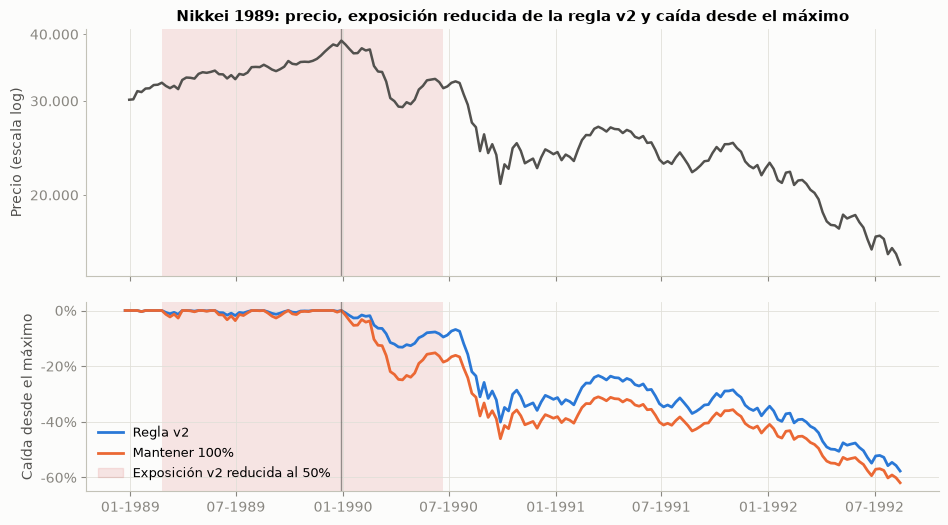

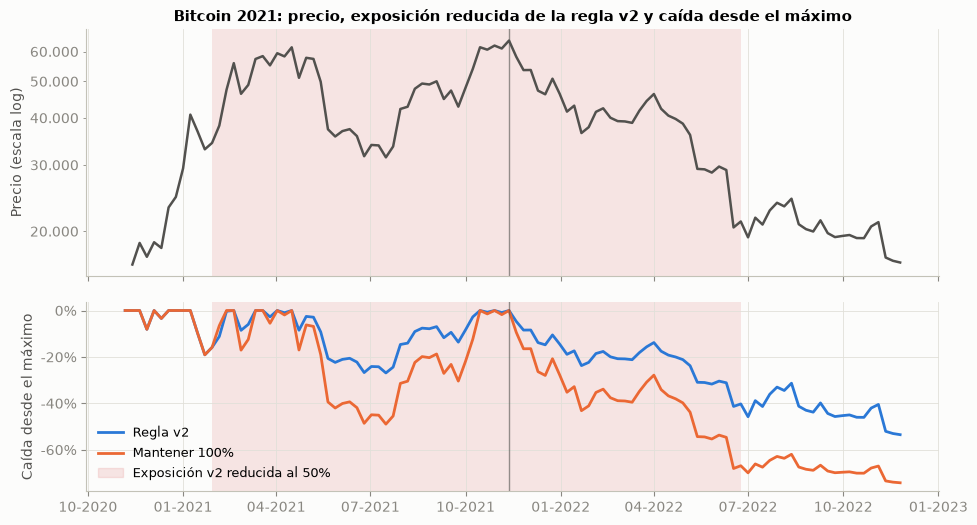

In [11]:
for nombre, res in resultados_fm.items():
    ep, precio = res["episodio"], res["precio"]
    r = res["evaluacion"]["retornos"].loc[ep["inicio"]:ep["valle"]]
    expo_v2 = res["evaluacion"]["reglas"]["v2"]["exposicion"].loc[r.index]
    regla_v2 = B.retornos_regla(r, expo_v2)

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True,
                                   gridspec_kw={"height_ratios": [1.3, 1], "hspace": 0.12})
    p = precio.loc[ep["inicio"]:ep["valle"]]
    ax1.plot(p.index, p, color=GRIS, lw=1.8)
    ax1.set_yscale("log")
    miles = plt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", "."))
    ax1.yaxis.set_major_formatter(miles)
    ax1.yaxis.set_minor_formatter(miles)
    ax1.set_ylabel("Precio (escala log)")
    ax1.set_title(f"{nombre}: precio, exposición reducida de la regla v2 y caída desde el máximo")
    ax2.plot(B.drawdown(regla_v2).index, B.drawdown(regla_v2), color=AZUL, lw=2, label="Regla v2")
    ax2.plot(B.drawdown(r).index, B.drawdown(r), color=NARANJA, lw=2, label="Mantener 100%")
    reducida = expo_v2 < 1
    grupos = (reducida != reducida.shift()).cumsum()[reducida]
    for ax in (ax1, ax2):
        for _, g in reducida[reducida].groupby(grupos):
            ax.axvspan(g.index[0] - pd.Timedelta(days=7), g.index[-1], color=ROJO, alpha=0.12, lw=0)
        ax.axvline(ep["peak"], color=GRIS, lw=1, alpha=0.6)
    ax2.fill_between([], [], color=ROJO, alpha=0.12, label="Exposición v2 reducida al 50%")
    ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax2.set_ylabel("Caída desde el máximo")
    ax2.legend(loc="lower left", frameon=False, fontsize=9)
    ax2.xaxis.set_major_formatter(mdates.DateFormatter("%m-%Y"))
    plt.show()

**Cómo leer el gráfico:** arriba, el precio en escala logarítmica, con una línea gris en el peak. Las franjas rojas marcan las semanas en que la v2 tiene 50% de exposición: el rojo más las 52 semanas de enfriamiento. Abajo, la caída desde el máximo de la v2 (azul) frente a mantener el 100% (naranja).

## 5. Tabla resumen de todos los episodios

In [12]:
def fila_resumen(muestra, nombre, tabla, anticipacion, evaluable=True, motivo=""):
    if not evaluable:
        return {"muestra": muestra, "episodio": nombre, "evaluable": "No", "motivo": motivo}
    return {"muestra": muestra, "episodio": nombre, "evaluable": "Sí", "motivo": motivo,
            "anticipación del rojo (sem.)": "sin señal" if anticipacion is None else anticipacion,
            "caída máx. mantener": tabla.loc["caida_maxima", "Mantener 100%"],
            "caída máx. v1": tabla.loc["caida_maxima", "v1"], "caída máx. v2": tabla.loc["caida_maxima", "v2"],
            "percentil placebo v1": tabla.loc["percentil_placebo", "v1"],
            "percentil placebo v2": tabla.loc["percentil_placebo", "v2"],
            "(a) v2 reduce la caída": tabla.loc["caida_maxima", "v2"] > tabla.loc["caida_maxima", "Mantener 100%"],
            "(b) percentil v2 < 20%": bool(tabla.loc["percentil_placebo", "v2"] < 20)}

filas = [fila_resumen("Dentro", f"Nasdaq {n}", t, B.anticipacion_rojo(colores_a, episodios_a[n]["peak"]))
         for n, t in tablas_a.items()]
filas.append(fila_resumen("Dentro", "Nasdaq periodo completo", B.tabla_ventana(evaluacion_a), "—"))
tb = tabla_b["Costo 0%"]
filas.append({"muestra": "Dentro", "episodio": "Cartera B 2018-hoy (9 acciones)", "evaluable": "Sí",
              "motivo": "sesgo de supervivencia", "caída máx. mantener": tb.loc["caida_maxima", "Mantener 100%"],
              "caída máx. v1": tb.loc["caida_maxima", "v1"], "caída máx. v2": tb.loc["caida_maxima", "v2"],
              "percentil placebo v1": tb.loc["percentil_placebo", "v1"],
              "percentil placebo v2": tb.loc["percentil_placebo", "v2"],
              "(a) v2 reduce la caída": tb.loc["caida_maxima", "v2"] > tb.loc["caida_maxima", "Mantener 100%"],
              "(b) percentil v2 < 20%": bool(tb.loc["percentil_placebo", "v2"] < 20)})
for nombre in EPISODIOS_FM:
    if nombre in resultados_fm:
        res = resultados_fm[nombre]
        filas.append(fila_resumen("Fuera", nombre, res["tabla"], res["anticipacion"]))
    else:
        filas.append(fila_resumen("Fuera", nombre, None, None, False, evaluabilidad.loc[nombre, "motivo"]))

resumen_episodios = pd.DataFrame(filas).set_index(["muestra", "episodio"])
resumen_episodios.to_csv(C.DIR_OUTPUTS / "resumen_episodios_v1_v2.csv")
resumen_episodios.style.format({c: "{:.1%}" for c in ["caída máx. mantener", "caída máx. v1", "caída máx. v2"]}
                               | {c: "{:.1f}" for c in ["percentil placebo v1", "percentil placebo v2"]},
                               na_rep="—")

## 6. Criterio de éxito (fijado antes de ver los resultados)

La v2 se valida si, **en la mayoría de los episodios fuera de muestra evaluables**, cumple (a) y (b) a la vez.

In [13]:
fuera = resumen_episodios.loc["Fuera"]
evaluables = fuera[fuera["evaluable"] == "Sí"]
cumplen = evaluables[(evaluables["(a) v2 reduce la caída"] == True) & (evaluables["(b) percentil v2 < 20%"] == True)]
n_eval, n_ok = len(evaluables), len(cumplen)
validada = n_eval > 0 and n_ok > n_eval / 2

print(f"Episodios fuera de muestra solicitados: {len(fuera)} | evaluables: {n_eval} "
      f"({', '.join(evaluables.index) or 'ninguno'})")
print(f"Cumplen (a) y (b): {n_ok} de {n_eval}")
for nombre, fila in evaluables.iterrows():
    print(f"  {nombre}: (a) reduce la caída = {fila['(a) v2 reduce la caída']} "
          f"({fila['caída máx. v2']:.1%} vs. {fila['caída máx. mantener']:.1%}); "
          f"(b) percentil placebo = {fila['percentil placebo v2']:.1f} {'< 20' if fila['(b) percentil v2 < 20%'] else '≥ 20'}")
print("\nVEREDICTO:", "REGLA v2 VALIDADA" if validada else "REGLA v2 NO VALIDADA según el criterio fijado")

Episodios fuera de muestra solicitados: 4 | evaluables: 2 (Nikkei 1989, Bitcoin 2021)
Cumplen (a) y (b): 1 de 2
  Nikkei 1989: (a) reduce la caída = True (-57.7% vs. -61.9%); (b) percentil placebo = 53.6 ≥ 20
  Bitcoin 2021: (a) reduce la caída = True (-53.5% vs. -74.2%); (b) percentil placebo = 13.2 < 20

VEREDICTO: REGLA v2 NO VALIDADA según el criterio fijado


### Cómo leer el veredicto

- **Dos episodios fuera de muestra son evaluables: Nikkei 1989 y Bitcoin 2021.** Shanghái 2007 y 2015 quedan fuera porque la serie no pasa la validación para índices (hueco de 13 días hábiles en 1999; sección 4.1).
- **En ambos episodios la v2 reduce la caída máxima** frente a mantener el 100%, así que (a) se cumple.
- **(b) se cumple en Bitcoin 2021** (percentil ~13 < 20) **pero no en el Nikkei 1989** (~54): ahí, reglas aleatorias con el mismo tiempo reducido logran resultados comparables.
- Cumplen (a) y (b) **1 de 2** episodios evaluables. **No es mayoría, así que la v2 no se valida.**
- **Nikkei 1989:** el rojo se encendió en febrero de 1989, 45 semanas antes del peak, y se apagó en junio. El enfriamiento de 52 semanas terminó en junio de 1990, pero la caída siguió hasta agosto de 1992. La v2 protegió el inicio, no el resto de la caída.
- **Bitcoin 2021:** el rojo se encendió en enero de 2021, 42 semanas antes del peak, y el enfriamiento cubrió hasta mediados de 2022.
- Como establece el criterio, **no se prueban otras variantes**. Con la evidencia disponible, **el KPI IL5 se presenta como calidad de detección**: el rojo anticipa los tres peaks evaluables (puntocom, Nikkei y Bitcoin) y no marca como burbuja las crisis de 2008 y 2022. **No se presenta como retorno.**
- Dentro de muestra, la v2 sí supera al placebo en el Nasdaq completo. Pero ese es justamente el episodio que inspiró la regla, y por eso no cuenta como validación.

## 7. Conclusiones y limitaciones

1. **El detector aporta información:** el rojo anticipa el peak en la puntocom (11 semanas), el Nikkei 1989 (45) y Bitcoin 2021 (42), y no confunde caídas sin burbuja (2008, 2022) con burbujas.
2. **Convertir esa información en una regla de exposición es más difícil:** la v1 vuelve al 100% en la caída. La v2 corrige eso dentro de muestra y reduce la caída en los dos episodios fuera de muestra. Supera al placebo en Bitcoin, pero no en el Nikkei, así que no alcanza la mayoría que exige el criterio fijado.
3. **La validación fuera de muestra sigue acotada:** de cuatro episodios propuestos, dos son evaluables. Shanghái queda excluido por un hueco de datos de 13 días hábiles en 1999.
4. **Cambio de regla después de ver resultados:** declarado en las decisiones de diseño (`docs/metodologia.md`), y controlado con parámetros fijados antes, validación fuera de muestra y un criterio de éxito definido de antemano.